# Student Details
## Name: Neeraj R Rugi
## SRN: PES2UG24CS311

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Practical Notebook: Preparing a 3-D Imaging Case Review

### Background

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Work through each **`# TODO`** section. Use the **Reflection** prompts to explain your reasoning using your own explanation. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Execute this supplied cell without changes. It imports the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — Calculating the Imaging Workload (Request #1)

**Practical context:** The voxel count and rendering workload are useful inputs when estimating image-storage and workstation requirements.

**Concept being applied:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**Tasks to complete:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0
samples_per_frame = 512 * 300 * 512
samples_video = samples_per_frame * 120
samples_video_ert = samples_video * (1 - 0.35)

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 6,134,169,600


**Think about and explain:** Ignoring anisotropic spacing would make coronal and sagittal anatomy appear stretched or compressed along the z direction, so distances and shapes would be wrong. It would also misplace the cross-sectional geometry relative to the other planes, producing incorrect measurements and misleading spatial relationships.


## Task 2 — Locate the Lesion Across Orthogonal Views (Request #2)

**Practical context:** Radiology review commonly uses three linked orthogonal slices, with a shared cursor indicating the same location in each plane.

**Concept being applied:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**Tasks to complete:**
1. Determine the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. For evaluation purposes only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

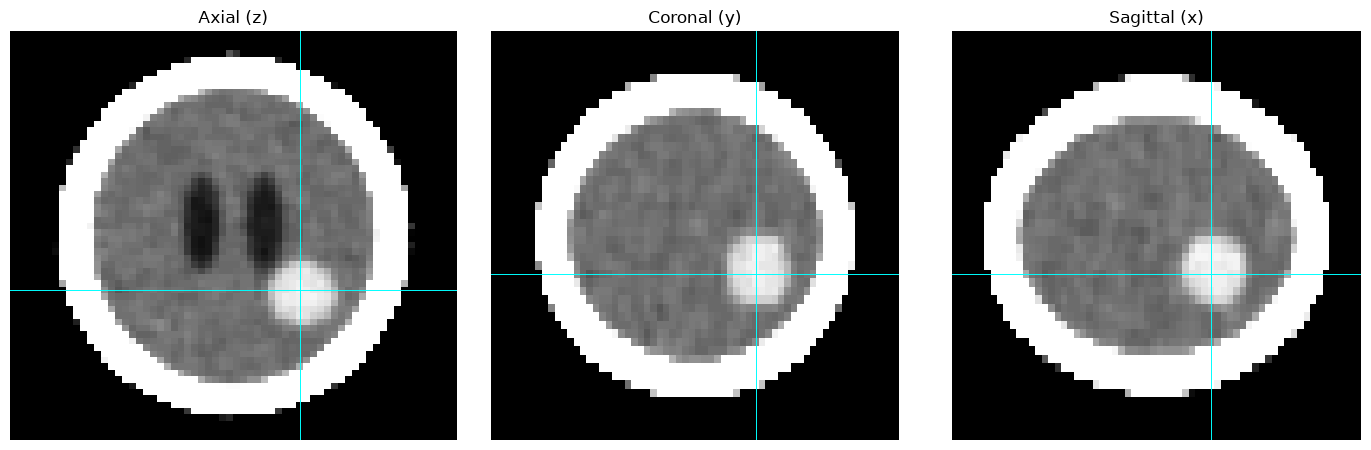

Centroid voxel (np.int64(28), np.int64(40), np.int64(41)); distance from evaluation centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside
cc, n_cc = ndimage.label(candidates)
sizes = np.bincount(cc.ravel()); sizes[0] = 0
lesion = cc == sizes.argmax()
cz, cy, cx = np.rint(ndimage.center_of_mass(lesion)).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [(vol[cz], "Axial (z)", cy, cx, None), (vol[:, cy, :], "Coronal (y)", cz, cx, ASPECT), (vol[:, :, cx], "Sagittal (x)", cz, cy, ASPECT)]
for ax, (sl, title, hy, hx, aspect) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", aspect=aspect if aspect is not None else "auto")
    ax.axhline(hy, color="cyan", lw=0.7); ax.axvline(hx, color="cyan", lw=0.7); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
distance_mm = np.linalg.norm((np.array([cz, cy, cx]) - truth_centroid) * np.array(SPACING))
print(f"Centroid voxel {(cz, cy, cx)}; distance from evaluation centroid: {distance_mm:.2f} mm")


**Think about and explain:** The thin partial volume shell is eroded so that voxels containing mixtures of skull, CSF and brain do not fall within the tumour HU range. Thresholding of the images alone would not be reliable due to overlapping intensity ranges. Erosion provides a spatial constraint on the interior of these tissues. This is applied prior to connected component selection.


## Task 3 — Measuring Volume Across Segmentation Thresholds (Request #3)

**Practical context:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Concept being applied:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**Tasks to complete:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


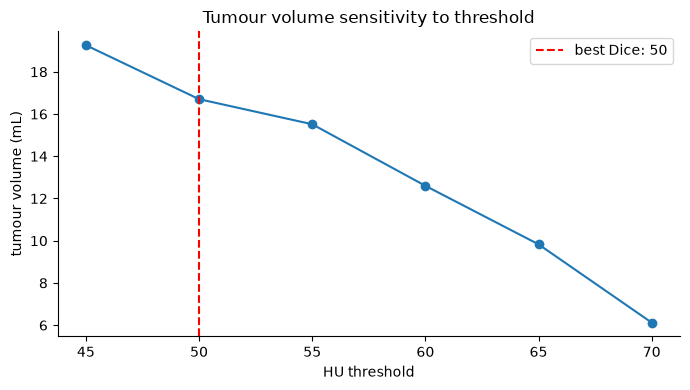

Reportable threshold-sensitivity range: 6.12?19.26 mL


In [4]:
truth = labels == 5
rows = []
for c in [45, 50, 55, 60, 65, 70]:
    threshold_cc, _ = ndimage.label(vol > c)
    component_id = threshold_cc[cz, cy, cx]
    segmentation = threshold_cc == component_id
    n = int(segmentation.sum())
    dice = 2 * np.logical_and(segmentation, truth).sum() / (segmentation.sum() + truth.sum())
    rows.append({"threshold": c, "voxels": n, "volume_ml": n * VOXEL_MM3 / 1000, "dice": dice})

table = pd.DataFrame(rows)
display(table)
best_threshold = table.loc[table.dice.idxmax(), "threshold"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_ml, "o-"); ax.axvline(best_threshold, color="red", ls="--", label=f"best Dice: {best_threshold:g}")
ax.set(xlabel="HU threshold", ylabel="tumour volume (mL)", title="Tumour volume sensitivity to threshold"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Reportable threshold-sensitivity range: {table.volume_ml.min():.2f}?{table.volume_ml.max():.2f} mL")


**Think about and explain:** My choice of threshold will be guided by my assessment of the MPR, by radiologists and the consistency of the segmentation between thresholds close to my choice. This will be documented in the scan protocol. The result will be shown as an uncertainty band or error bars showing the central value with the maximum range in sensitivity. Low, mid and high values will be overlaid on the segmentation.


## Task 4 — Building a 3-D View of the Lesion (Request #4)

**Practical context:** A pre-surgical 3-D view should communicate where the lesion sits relative to nearby anatomy, including the ventricles.

**Concept being applied:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**Tasks to complete:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), next to one another with the bone render.
4. Give the figure a conclusion-style title.

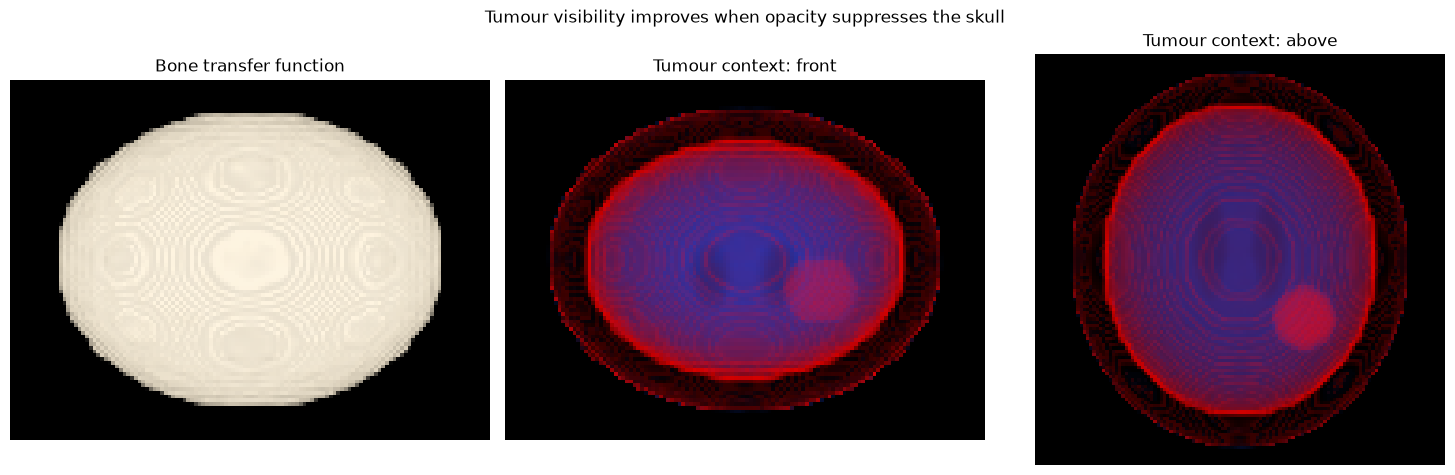

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

tumour_tf = make_tf([(-1000, (0, 0, 0), 0), (4, (0, 0, 0), 0), (20, (0.1, 0.3, 1.0), 0.015), (45, (0.1, 0.3, 1.0), 0.015), (55, (1.0, 0.0, 0.0), 0.12), (90, (1.0, 0.0, 0.0), 0.12), (200, (0, 0, 0), 0.005), (400, (0, 0, 0), 0.005), (1500, (0, 0, 0), 0)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (rgb, alpha), title in zip(axes, [render(vol, bone_tf, axis=1), render(vol, tumour_tf, axis=1), render(vol, tumour_tf, axis=0)], ["Bone transfer function", "Tumour context: front", "Tumour context: above"]):
    ax.imshow(np.clip(rgb, 0, 1)); ax.set_title(title); ax.axis("off")
fig.suptitle("Tumour visibility improves when opacity suppresses the skull")
plt.tight_layout(); plt.show()


**Think about and explain:** This low-intensity red halo is caused by partial volume and intensity mixing of different materials within a voxel causing the boundary voxel to appear tumour-like. This can be solved by using a segmentation/connected component mask (or some form of isosurface with spatial clean up). Using a transfer function will not solve this issue as you are only mapping the intensity to a particular colour/opacity. You will have no idea if the HU value is part of the tumour or a boundary without any spatial information.


**Your concluding recommendation:** This shows a small region of damage in the centre of the brain at voxel position (z=28, y=40, x=41). The volume of damage is dependent on the threshold used and ranges from 6.12?19.26 mL. The first image to be shown should be the 3 plane MPR. This provides information of the lesion's inner structure as there is no ambiguity from viewing it in orthoganal slices. The segmentation view should then be displayed showing the segmentation and selected threshold range. As the lesion has been segmented this gives the ability to measure it however changing the threshold values will affect the shape. The 3-D view helps provide some context however the transfer function can be confusing when looking at intensity overlaps. The partial volume edge cannot be identified from this view on its own.
